# Fruit Classification with VGG-16 (Transfer Learning)

An end-to-end PyTorch project: dataset discovery → EDA → stratified split → preprocessing → fine-tuning → evaluation → inference.

**Dataset:** `dataset/image/` — 16 classes (15 fruits + `no fruit`)  
**Model:** ResNet50 pre-trained on ImageNet  

## 1. Setup

Import the required libraries, fix the random seed, and select the compute device.

> Requirements: `torch`, `torchvision`, `pandas`, `numpy`, `matplotlib`, `scikit-learn`, `pillow`.

In [123]:
import random
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 16
DATA_DIR = Path("dataset/image")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
print("Device:", device)

Device: cuda


## 2. Dataset Discovery

Auto-discover class folders, keep only image files, and build a manifest

In [2]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".gif"}

# Get all classes
class_names = sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir())

class_to_idx = {name: i for i, name in enumerate(class_names)}
idx_to_class = {i: name for name, i in class_to_idx.items()}

num_classes = len(class_names)

# Collect all images
rows = []

for name in class_names:
    for path in (DATA_DIR / name).iterdir():
        if path.is_file() and path.suffix.lower() in IMG_EXTS:
            rows.append({
                "path": str(path),
                "class_name": name,
                "label": class_to_idx[name]
            })

# Create DataFrame
df = pd.DataFrame(rows)

print(f"Classes: {num_classes}")
print(f"Total Images: {len(df)}")

display(df.head())

Classes: 16
Total Images: 3745


,path,class_name,label
0,dataset\image\apple fruit\Image_1.jpg,apple fruit,0
1,dataset\image\apple fruit\Image_10.jpg,apple fruit,0
2,dataset\image\apple fruit\Image_10_aug_1.jpg,apple fruit,0
3,dataset\image\apple fruit\Image_10_aug_2.jpg,apple fruit,0
4,dataset\image\apple fruit\Image_10_aug_3.jpg,apple fruit,0


### Class mappings

Explicit class-to-index and index-to-class dictionaries, used by the dataset, model, and inference.

In [3]:
print("class_to_idx =", class_to_idx)
print("idx_to_class =", idx_to_class)

class_to_idx = {'apple fruit': 0, 'banana fruit': 1, 'cherry fruit': 2, 'chickoo fruit': 3, 'coconut fruit': 4, 'dates fruit': 5, 'grapes fruit': 6, 'guava fruit': 7, 'kiwi fruit': 8, 'mango fruit': 9, 'no fruit': 10, 'orange fruit': 11, 'pineapple fruit': 12, 'pomegranate fruit': 13, 'strawberry fruit': 14, 'watermelon fruit': 15}
idx_to_class = {0: 'apple fruit', 1: 'banana fruit', 2: 'cherry fruit', 3: 'chickoo fruit', 4: 'coconut fruit', 5: 'dates fruit', 6: 'grapes fruit', 7: 'guava fruit', 8: 'kiwi fruit', 9: 'mango fruit', 10: 'no fruit', 11: 'orange fruit', 12: 'pineapple fruit', 13: 'pomegranate fruit', 14: 'strawberry fruit', 15: 'watermelon fruit'}


## 3. Exploratory Data Analysis

### 3.1 Class distribution

Total original images: 3745


,images,share_%
class_name,,
apple fruit,240,6.4
banana fruit,240,6.4
cherry fruit,240,6.4
chickoo fruit,240,6.4
coconut fruit,240,6.4
dates fruit,240,6.4
grapes fruit,240,6.4
guava fruit,240,6.4
kiwi fruit,240,6.4


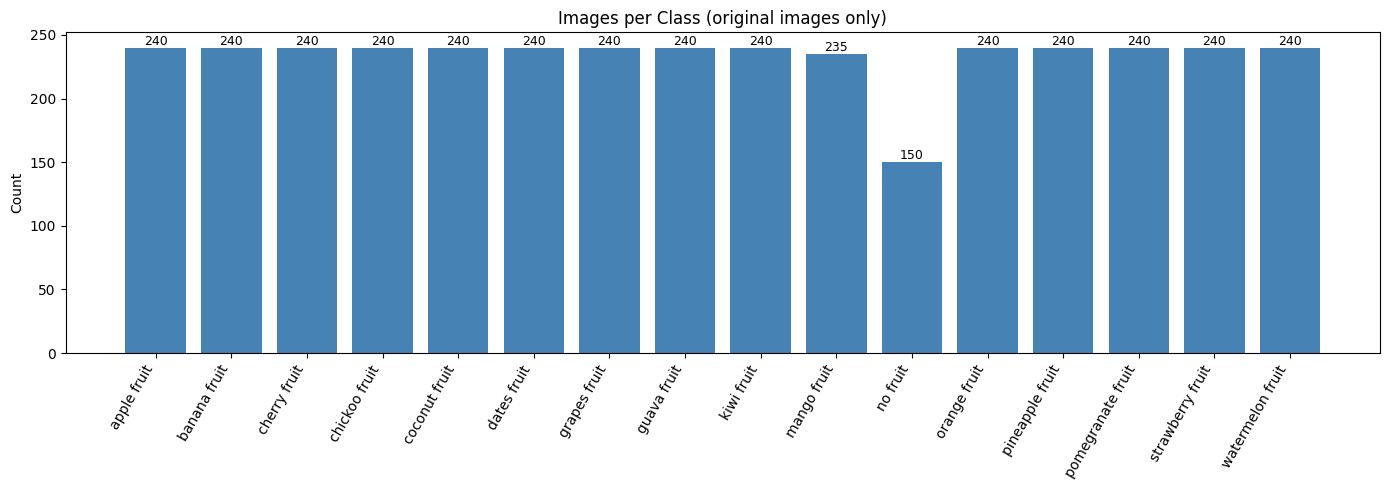

In [4]:
counts = df["class_name"].value_counts().reindex(class_names)
summary = counts.rename("images").to_frame()
summary["share_%"] = (summary["images"] / len(df) * 100).round(1)

print(f"Total original images: {len(df)}")
display(summary)

fig, ax = plt.subplots(figsize=(14, 5))
bars = ax.bar(counts.index, counts.values, color="steelblue")
ax.bar_label(bars, fontsize=9)
ax.set_title("Images per Class (original images only)")
ax.set_ylabel("Count")
plt.setp(ax.get_xticklabels(), rotation=60, ha="right")
plt.tight_layout()
plt.show()

### 3.2 Sample images

One random image from every class.

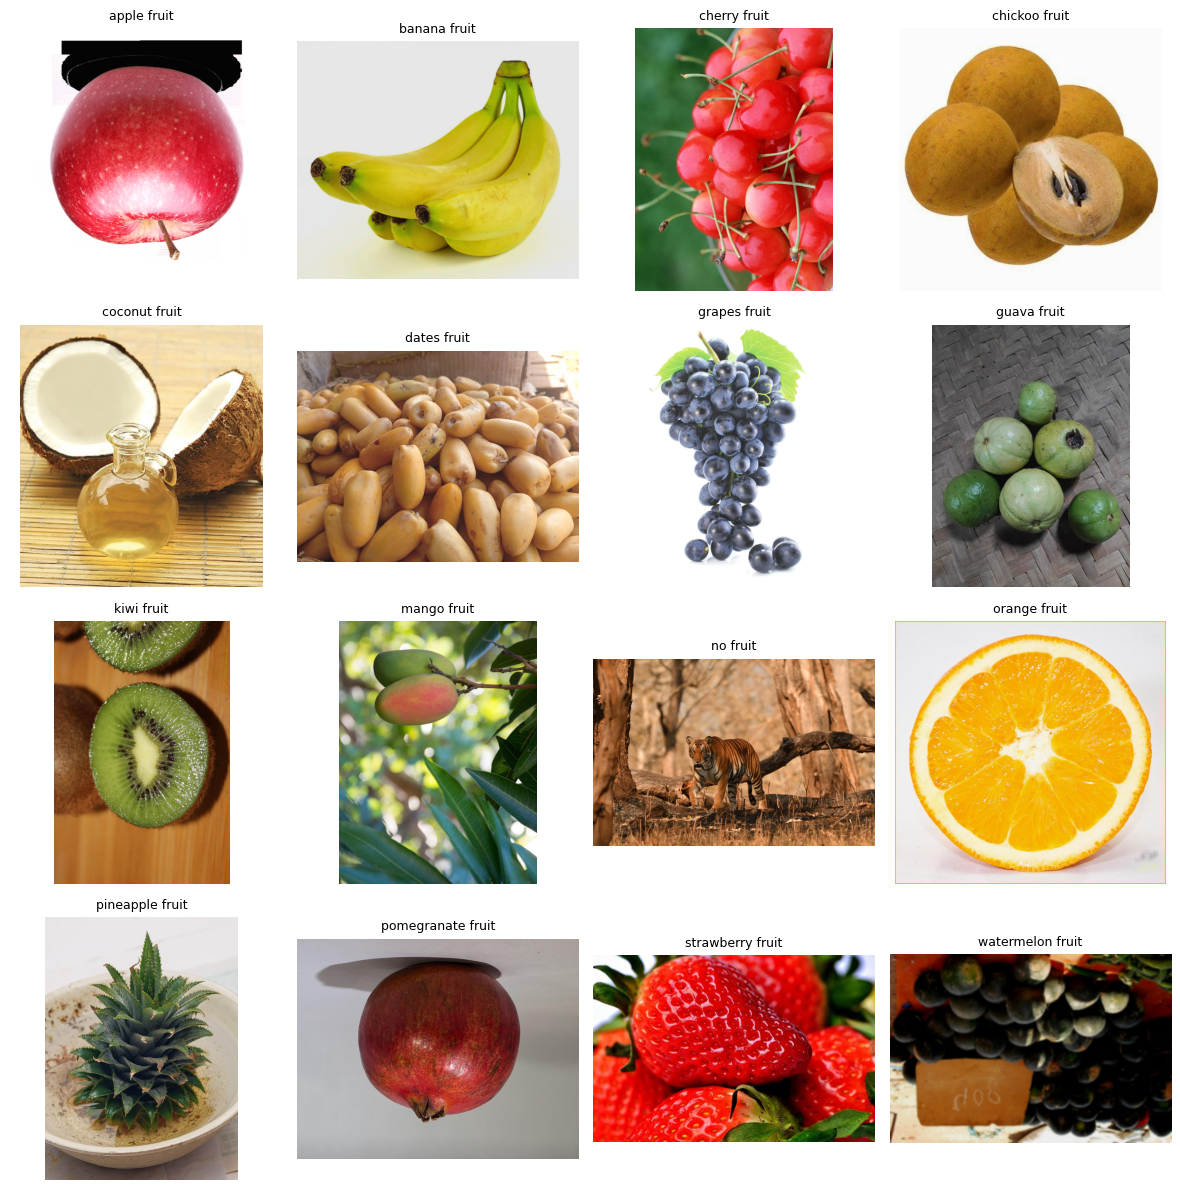

In [7]:
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for ax, name in zip(axes.ravel(), class_names):
    path = df.loc[df["class_name"] == name].sample(1, random_state=SEED)["path"].iloc[0]
    with Image.open(path) as raw:
        image = ImageOps.exif_transpose(raw).convert("RGB")
    ax.imshow(image)
    ax.set_title(name, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

### 3.3 Image dimensions and corrupted files

Validate every file with PIL; corrupted images are reported and excluded from the split.

Valid images: 3745 | corrupted: 0


,width,height
count,3745.0,3745.0
mean,1405.3,1257.6
std,1019.2,873.8
min,167.0,145.0
25%,877.0,720.0
50%,1062.0,1000.0
75%,1600.0,1434.0
max,8256.0,8256.0


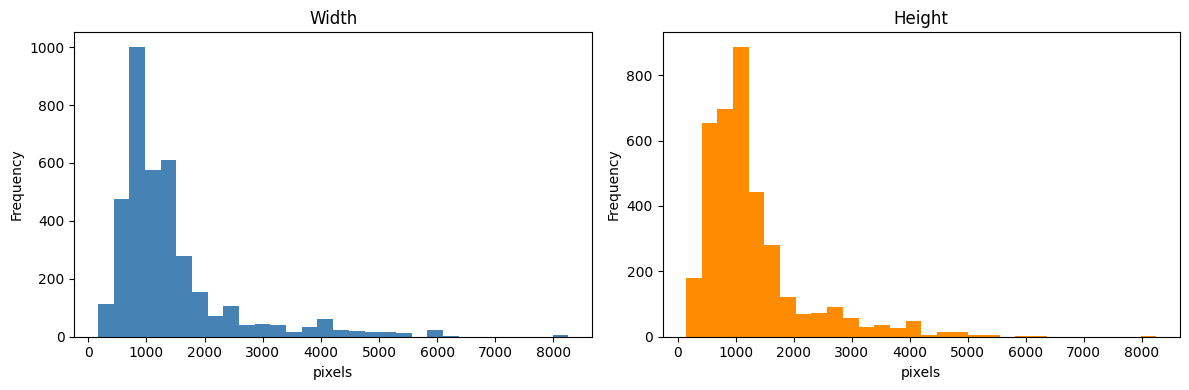

In [8]:
dims, corrupted = [], []
for row in df.itertuples():
    try:
        with Image.open(row.path) as image:
            image.verify()
        with Image.open(row.path) as image:
            dims.append((row.path, image.width, image.height))
    except Exception as exc:
        corrupted.append((row.path, str(exc)))

dims = pd.DataFrame(dims, columns=["path", "width", "height"])
df = df[df["path"].isin(dims["path"])].reset_index(drop=True)

print(f"Valid images: {len(df)} | corrupted: {len(corrupted)}")
for path, error in corrupted:
    print("  corrupted:", path, "-", error)
display(dims[["width", "height"]].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
dims["width"].plot.hist(bins=30, ax=axes[0], color="steelblue", title="Width")
dims["height"].plot.hist(bins=30, ax=axes[1], color="darkorange", title="Height")
for ax in axes:
    ax.set_xlabel("pixels")
plt.tight_layout()
plt.show()

## 4. Stratified Split (80 / 10 / 10)

Split original images only. Augmented copies never enter the split, so an image and its augmentations cannot leak across train, validation, and test.

In [9]:
train_df, temp_df = train_test_split(
    df, test_size=0.20, stratify=df["label"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

for name, part in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"{name:>10}: {len(part):4d} images ({len(part) / len(df):.0%})")

split_counts = pd.DataFrame({
    "train": train_df["class_name"].value_counts(),
    "val": val_df["class_name"].value_counts(),
    "test": test_df["class_name"].value_counts(),
}).reindex(class_names)
display(split_counts)

     Train: 2996 images (80%)
Validation:  374 images (10%)
      Test:  375 images (10%)


,train,val,test
class_name,,,
apple fruit,192,24,24
banana fruit,192,24,24
cherry fruit,192,24,24
chickoo fruit,192,24,24
coconut fruit,192,24,24
dates fruit,192,24,24
grapes fruit,192,24,24
guava fruit,192,24,24
kiwi fruit,192,24,24


## 5. Preprocessing and DataLoaders

Images are converted to RGB, resized to 224×224, converted to tensors, and normalized with ImageNet statistics. Training adds light on-the-fly augmentation; validation and test are deterministic.

In [10]:
train_tfms = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

eval_tfms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
print(train_tfms)

Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.8, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


### Dataset class

Loads RGB images, applies a transform, and safely falls back to a blank image if a file cannot be read.

In [11]:
class FruitDataset(Dataset):
    def __init__(self, frame, transform):
        self.paths = frame["path"].tolist()
        self.labels = frame["label"].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        try:
            with Image.open(self.paths[index]) as raw:
                image = ImageOps.exif_transpose(raw).convert("RGB")
        except Exception:
            image = Image.new("RGB", (IMG_SIZE, IMG_SIZE))
        return self.transform(image), self.labels[index]

### DataLoaders

`num_workers=0` keeps the notebook stable on Windows. Increase it on Linux for faster loading.

In [12]:
train_ds = FruitDataset(train_df, train_tfms)
val_ds = FruitDataset(val_df, eval_tfms)
test_ds = FruitDataset(test_df, eval_tfms)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

images, labels = next(iter(train_loader))
print("Image batch:", tuple(images.shape), images.dtype)
print("Label batch:", tuple(labels.shape))

Image batch: (16, 3, 224, 224) torch.float32
Label batch: (16,)


## 6. Model: VGG-16 Transfer Learning

Load ImageNet weights, freeze the backbone, and replace the final layer with a 16-class head.

In [97]:
VGG16_model = models.vgg16(weights=models.VGG16_Weights.DEFAULT)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to C:\Users\surya/.cache\torch\hub\checkpoints\vgg16-397923af.pth


100%|██████████| 528M/528M [01:13<00:00, 7.52MB/s] 


In [98]:
VGG16 = VGG16_model

In [99]:
VGG16.features

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU(inplace=True)
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): ReLU(inplace=True)
  (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU(inplace=True)
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU(inplace=True)
  (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (13): ReLU(inplace=True)
  (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (15): ReLU(inplace=True)
  (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (17): Conv2d(256, 512, kernel_si

In [100]:
VGG16.classifier

Sequential(
  (0): Linear(in_features=25088, out_features=4096, bias=True)
  (1): ReLU(inplace=True)
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=4096, out_features=4096, bias=True)
  (4): ReLU(inplace=True)
  (5): Dropout(p=0.5, inplace=False)
  (6): Linear(in_features=4096, out_features=1000, bias=True)
)

In [101]:
for param in VGG16.parameters():
    param.requires_grad = False

In [102]:
# VGG16.classifier[2] = nn.Dropout(0.5)
VGG16.classifier[3] = nn.Linear(4096, 512)
# VGG16.classifier[4] = nn.ReLU()
# VGG16.classifier[5] = nn.Dropout(0.5)
VGG16.classifier[6] = nn.Linear(512, num_classes)

In [103]:
VGG16.classifier[3].weight.requires_grad = True
VGG16.classifier[6].weight.requires_grad = True

In [104]:
VGG16.classifier

Sequential(
  (0): Linear(in_features=25088, out_features=4096, bias=True)
  (1): ReLU(inplace=True)
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=4096, out_features=512, bias=True)
  (4): ReLU(inplace=True)
  (5): Dropout(p=0.5, inplace=False)
  (6): Linear(in_features=512, out_features=16, bias=True)
)

In [105]:
VGG16 = VGG16.to(device)

In [107]:
lr = 0.0001
epochs = 50
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(VGG16.classifier.parameters(), lr=lr)

### Fit helper

Runs training and validation, then saves the checkpoint whenever validation accuracy improves.

In [108]:
# Store training history
history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

# Early stopping configuration
patience = 3
min_delta = 0.001
counter = 0
best_val_loss = float("inf")

for epoch in range(epochs):

    start_time = time.time()

    # ==========================
    #       TRAINING
    # ==========================

    VGG16.train()

    total_train_loss = 0
    train_correct = 0
    train_samples = 0

    for batch_features, batch_labels in train_loader:

        batch_features = batch_features.to(device)
        batch_labels = batch_labels.to(device)

        # Forward pass
        output = VGG16(batch_features)

        # Calculate loss
        loss = criterion(output, batch_labels)

        # Backward pass
        optimizer.zero_grad()
        loss.backward()

        # Update weights
        optimizer.step()

        # Calculate total loss
        batch_size = batch_labels.size(0)

        total_train_loss += loss.item() * batch_size

        # Calculate accuracy
        predicted = torch.argmax(output, dim=1)

        train_correct += (predicted == batch_labels).sum().item()
        train_samples += batch_size

    # Average training metrics
    avg_train_loss = total_train_loss / train_samples
    train_acc = train_correct / train_samples


    # ==========================
    #       VALIDATION
    # ==========================

    VGG16.eval()

    total_val_loss = 0
    val_correct = 0
    val_samples = 0

    with torch.no_grad():

        for batch_features, batch_labels in val_loader:

            batch_features = batch_features.to(device)
            batch_labels = batch_labels.to(device)

            # Forward pass
            output = VGG16(batch_features)

            # Calculate loss
            loss = criterion(output, batch_labels)

            batch_size = batch_labels.size(0)

            total_val_loss += loss.item() * batch_size

            # Calculate accuracy
            predicted = torch.argmax(output, dim=1)

            val_correct += (predicted == batch_labels).sum().item()
            val_samples += batch_size

    # Average validation metrics
    avg_val_loss = total_val_loss / val_samples
    val_acc = val_correct / val_samples


    # ==========================
    #       STORE HISTORY
    # ==========================

    history["train_loss"].append(avg_train_loss)
    history["train_acc"].append(train_acc)

    history["val_loss"].append(avg_val_loss)
    history["val_acc"].append(val_acc)


    # ==========================
    #       EARLY STOPPING
    # ==========================

    if avg_val_loss < best_val_loss - min_delta:

        best_val_loss = avg_val_loss
        counter = 0

        # Save best model
        torch.save(VGG16.state_dict(), "best_fruit_vgg16.pth")

    else:
        counter += 1

    # Print epoch information
    elapsed_time = time.time() - start_time

    print(
        f"Epoch: {epoch+1}/{epochs} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%} | "
        f"Time: {elapsed_time:.1f}s"
    )

    # Stop training if patience is reached
    if counter >= patience:

        print(f"\nEarly Stopping at Epoch {epoch+1}")
        break

Epoch: 1/50 | Train Loss: 1.4526 | Train Acc: 60.18% | Val Loss: 0.5027 | Val Acc: 87.43% | Time: 113.3s
Epoch: 2/50 | Train Loss: 0.6170 | Train Acc: 82.74% | Val Loss: 0.3421 | Val Acc: 89.84% | Time: 113.2s
Epoch: 3/50 | Train Loss: 0.4445 | Train Acc: 87.08% | Val Loss: 0.2338 | Val Acc: 93.85% | Time: 114.5s
Epoch: 4/50 | Train Loss: 0.3219 | Train Acc: 91.12% | Val Loss: 0.2202 | Val Acc: 93.58% | Time: 113.4s
Epoch: 5/50 | Train Loss: 0.2685 | Train Acc: 92.46% | Val Loss: 0.1705 | Val Acc: 94.92% | Time: 113.0s
Epoch: 6/50 | Train Loss: 0.2264 | Train Acc: 93.83% | Val Loss: 0.1284 | Val Acc: 97.06% | Time: 112.6s
Epoch: 7/50 | Train Loss: 0.1961 | Train Acc: 94.39% | Val Loss: 0.1012 | Val Acc: 97.59% | Time: 112.7s
Epoch: 8/50 | Train Loss: 0.1653 | Train Acc: 95.19% | Val Loss: 0.1014 | Val Acc: 97.33% | Time: 112.4s
Epoch: 9/50 | Train Loss: 0.1567 | Train Acc: 95.59% | Val Loss: 0.1115 | Val Acc: 97.59% | Time: 119.2s
Epoch: 10/50 | Train Loss: 0.1385 | Train Acc: 95.86% |

### Training curves

Loss and accuracy across both phases; the dashed line marks the start of fine-tuning.

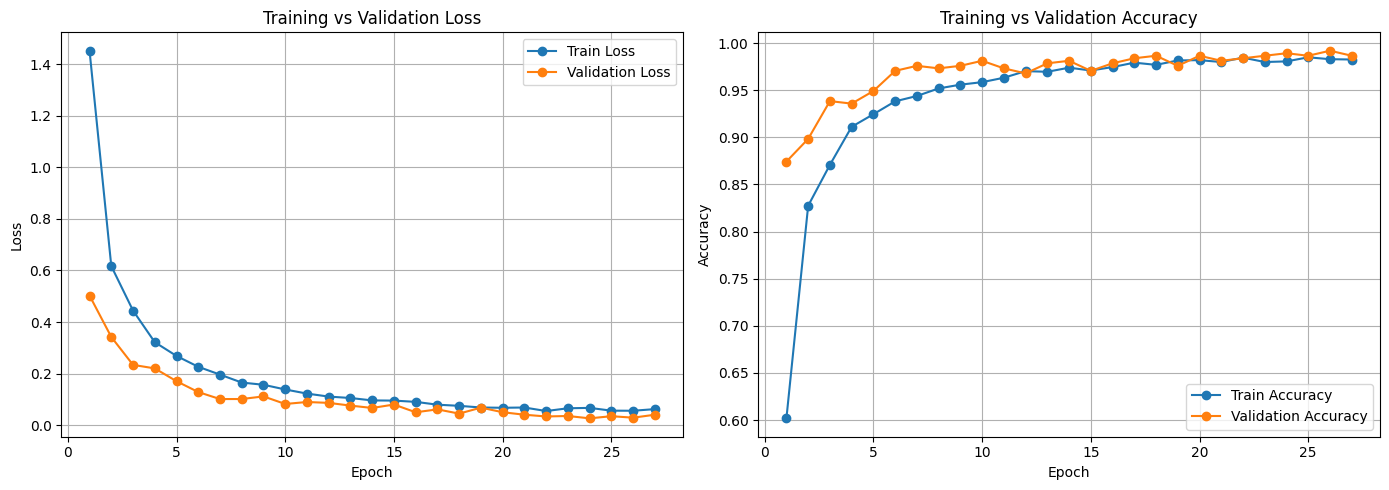

In [109]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs_range = range(1, len(history["train_loss"]) + 1)

# LOSS GRAPH

axes[0].plot(epochs_range, history["train_loss"], marker="o", label="Train Loss")
axes[0].plot(epochs_range, history["val_loss"], marker="o", label="Validation Loss")

axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# ACCURACY GRAPH

axes[1].plot(epochs_range, history["train_acc"], marker="o", label="Train Accuracy")
axes[1].plot(epochs_range, history["val_acc"], marker="o", label="Validation Accuracy")

axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)


plt.tight_layout()
plt.show()

In [116]:
VGG16.load_state_dict(
    torch.load(
        "best_fruit_vgg16.pth",
        map_location=device,
        weights_only=True
    )
)

VGG16 = VGG16.to(device)
VGG16.eval()

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

In [117]:
total_test_loss = 0
test_correct = 0
test_samples = 0

all_predictions = []
all_labels = []

VGG16.eval()

with torch.no_grad():

    for batch_features, batch_labels in test_loader:

        batch_features = batch_features.to(device)
        batch_labels = batch_labels.to(device)

        # Forward pass
        output = VGG16(batch_features)

        # Calculate loss
        loss = criterion(output, batch_labels)

        batch_size = batch_labels.size(0)

        total_test_loss += loss.item() * batch_size

        # Prediction
        predicted = torch.argmax(output, dim=1)

        test_correct += (predicted == batch_labels).sum().item()
        test_samples += batch_size

        # Store predictions and actual labels
        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(batch_labels.cpu().numpy())


# Calculate final metrics
test_loss = total_test_loss / test_samples
test_accuracy = test_correct / test_samples

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")

Test Loss: 0.0479
Test Accuracy: 98.13%


In [118]:
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=class_names,
        digits=4
    )
)

                   precision    recall  f1-score   support

      apple fruit     0.9231    1.0000    0.9600        24
     banana fruit     1.0000    1.0000    1.0000        24
     cherry fruit     1.0000    1.0000    1.0000        24
    chickoo fruit     0.9600    1.0000    0.9796        24
    coconut fruit     1.0000    1.0000    1.0000        24
      dates fruit     0.9600    1.0000    0.9796        24
     grapes fruit     0.9583    0.9583    0.9583        24
      guava fruit     0.9583    0.9583    0.9583        24
       kiwi fruit     1.0000    1.0000    1.0000        24
      mango fruit     1.0000    0.8750    0.9333        24
         no fruit     1.0000    0.8667    0.9286        15
     orange fruit     1.0000    1.0000    1.0000        24
  pineapple fruit     1.0000    1.0000    1.0000        24
pomegranate fruit     1.0000    1.0000    1.0000        24
 strawberry fruit     1.0000    1.0000    1.0000        24
 watermelon fruit     0.9600    1.0000    0.9796       

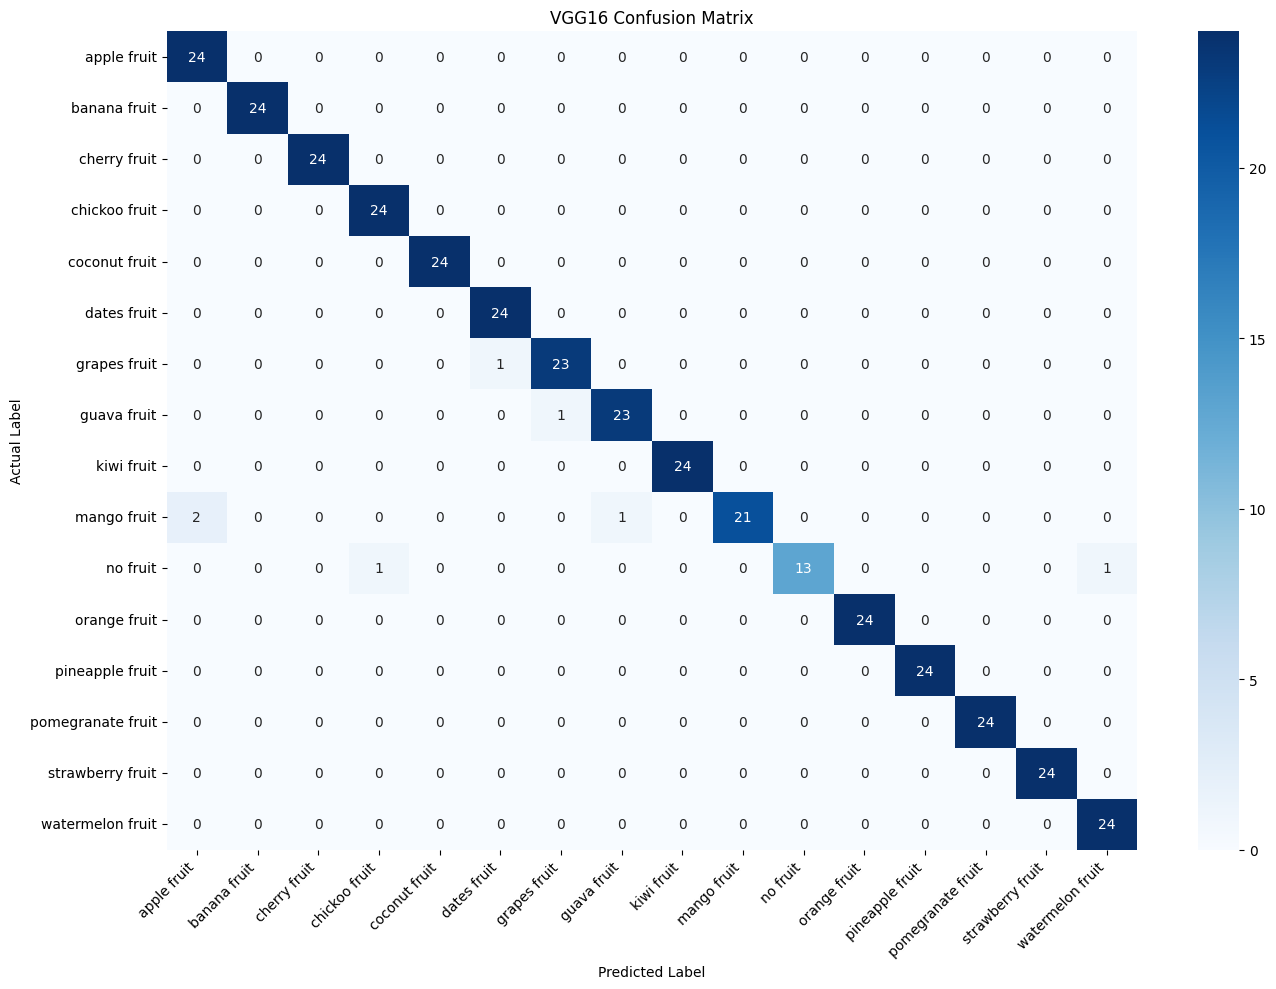

In [124]:
cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(14, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("VGG16 Confusion Matrix")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()